# Chinese world: birth + 35 vs active life
Three ways to place the same individuals in time. **Birth + 35** counts each person once, at age 35. **Birth + 25–70** counts each person in every year from age 25 to 70, whatever their death date. **Active life** counts each person in every year from their first to their last work, dated or estimated (`individual_enriched.first_work_date` → `last_work_date` in `cultura_enriched_v3.2`).

In [1]:
import duckdb
import matplotlib.pyplot as plt
import numpy as np
import polars as pl
from style import *

DB_PATH = '../../data/cultura/humans_clean_enriched_v3.duckdb'
ACTIVE_LIFE_DB_PATH = '../../data/cultura/cultura_enriched_v3.2.duckdb'

FIRST_YEAR, LAST_YEAR = -500, 1900
ZOOM_FIRST, ZOOM_LAST = 1550, 1750
POINT_AGE = 35
WIDE_START_AGE, WIDE_END_AGE = 25, 70
PRECISE = ['day', 'month', 'year']

SERIES = {
    'birth_35': ('Birth + 35 (each person once)', ORANGE, 1.0),
    'wide_25_70': ('Birth + 25–70 (death ignored)', GREEN, 2.2),
    'active_life': ('Active life (first to last work)', BLUE, 2.2),
}

apply_style()

## Load data — Chinese-world individuals with a birth year and an active life
Chinese-world individuals come from the polity matching of `humans_clean_enriched_v3`. Birth and active life come from `cultura_enriched_v3.2`: a birth year is either stated in Wikidata or estimated from the death and the cohort's mean age at death; the active life is read from dated works or estimated from the birth and the cohort's median ages at the first and last work. Individuals with only coarse dates have no birth year and are left out.

In [2]:
con = duckdb.connect(DB_PATH, read_only=True)
con.sql(f"ATTACH '{ACTIVE_LIFE_DB_PATH}' AS active_life_db (READ_ONLY)")
individuals = con.execute('''
    WITH chinese_polities AS (
        SELECT DISTINCT name FROM polity WHERE list_contains(world, 'Chinese world')
    ),
    chinese_individuals AS (
        SELECT DISTINCT entity.qid AS qid
        FROM (SELECT entity, unnest(polity) AS match FROM individual_enriched)
        WHERE match.polity.name IN (SELECT name FROM chinese_polities)
    )
    SELECT chinese_individuals.qid,
           active_life.birth_date.year                     AS birth_year,
           active_life.birth_date.precision                AS birth_precision,
           active_life.birth_date.source = 'wikidata'      AS birth_stated,
           active_life.first_work_date.year                AS active_life_start,
           active_life.last_work_date.year                 AS active_life_end,
           active_life.first_work_date.source              AS active_life_source
    FROM chinese_individuals
    JOIN active_life_db.individual_enriched AS active_life ON active_life.entity.qid = chinese_individuals.qid
''').pl()
con.close()

assert individuals['qid'].n_unique() == individuals.height
print(f'{individuals.height:,} Chinese-world individuals')
individuals = individuals.filter(pl.col('birth_year').is_not_null() & pl.col('birth_precision').is_in(PRECISE))
print(f'{individuals.height:,} with a birth year (day, month or year precision)')
individuals = individuals.filter(pl.col('active_life_start').is_not_null() & pl.col('active_life_end').is_not_null())
print(f'{individuals.height:,} with an active life')
print(f"{(~individuals['birth_stated']).sum():,} of them with an estimated birth year")
individuals.group_by('active_life_source', 'birth_stated').len().sort('len', descending=True)

88,845 Chinese-world individuals
87,629 with a birth year (day, month or year precision)
87,629 with an active life
29,289 of them with an estimated birth year


active_life_source,birth_stated,len
str,bool,u32
"""estimated""",true,57717
"""estimated""",false,29262
"""dated works""",true,623
"""dated works""",false,27


## Preprocessing
### Birth + 35 and active-life length

In [3]:
individuals = individuals.with_columns(
    (pl.col('birth_year') + POINT_AGE).alias('point_year'),
    (pl.col('active_life_end') - pl.col('active_life_start') + 1).alias('active_years'),
)
assert (individuals['active_years'] >= 1).all()
print(individuals['active_years'].describe())
individuals.sample(5, seed=0)

shape: (9, 2)
┌────────────┬───────────┐
│ statistic  ┆ value     │
│ ---        ┆ ---       │
│ str        ┆ f64       │
╞════════════╪═══════════╡
│ count      ┆ 87629.0   │
│ null_count ┆ 0.0       │
│ mean       ┆ 17.082884 │
│ std        ┆ 6.180773  │
│ min        ┆ 1.0       │
│ 25%        ┆ 15.0      │
│ 50%        ┆ 17.0      │
│ 75%        ┆ 23.0      │
│ max        ┆ 83.0      │
└────────────┴───────────┘


qid,birth_year,birth_precision,birth_stated,active_life_start,active_life_end,active_life_source,point_year,active_years
str,i64,str,bool,i64,i64,str,i64,i64
"""Q45609537""",1545,"""year""",true,1587,1598,"""estimated""",1580,12
"""Q16905661""",1138,"""year""",true,1186,1207,"""estimated""",1173,22
"""Q45586818""",1539,"""year""",true,1569,1592,"""estimated""",1574,24
"""Q20688908""",1486,"""year""",true,1529,1545,"""estimated""",1521,17
"""Q45674928""",650,"""year""",false,693,707,"""estimated""",685,15


### Yearly counts

In [4]:
years = pl.DataFrame({'year': np.arange(FIRST_YEAR, LAST_YEAR + 1)})

point_counts = individuals.group_by(pl.col('point_year').alias('year')).len('birth_35')


def window_counts(start, end, name):
    return (
        individuals.select(pl.int_ranges(start, end + 1).alias('year'))
        .explode('year')
        .group_by('year').len(name)
    )


active_life_counts = window_counts(pl.col('active_life_start'), pl.col('active_life_end'), 'active_life')
wide_counts = window_counts(pl.col('birth_year') + WIDE_START_AGE, pl.col('birth_year') + WIDE_END_AGE, 'wide_25_70')
yearly = (
    years.join(point_counts, on='year', how='left')
    .join(wide_counts, on='year', how='left')
    .join(active_life_counts, on='year', how='left')
    .with_columns(pl.col(list(SERIES)).fill_null(0))
)
print(f"individuals counted at birth + 35 in {FIRST_YEAR}–{LAST_YEAR}: {yearly['birth_35'].sum():,}")
yearly.filter(pl.col('year').is_between(1640, 1650))

individuals counted at birth + 35 in -500–1900: 85,243


year,birth_35,wide_25_70,active_life
i64,u32,u32,u32
1640,93,3103,1347
1641,86,3163,1402
1642,73,3259,1448
1643,86,3367,1481
1644,82,3469,1550
…,…,…,…
1646,95,3679,1648
1647,108,3752,1690
1648,101,3828,1782


### Check: are birth years rounded?
If birth years were rounded estimates, far more than 10% would end in 0 or 5. They do not, so the gap between the two series below comes from how people are counted, not from rounded dates.

In [5]:
in_range = individuals.filter(pl.col('birth_year').is_between(FIRST_YEAR, LAST_YEAR))
last_digit = in_range.with_columns((pl.col('birth_year') % 10).alias('last_digit'))
digit_shares = (
    last_digit.group_by('last_digit').len()
    .with_columns((100 * pl.col('len') / pl.col('len').sum()).round(1).alias('pct'))
    .sort('last_digit')
)
digit_shares

last_digit,len,pct
i64,u32,f64
0,8809,10.1
1,8765,10.0
2,8536,9.7
3,8757,10.0
4,8858,10.1
5,8530,9.7
6,8970,10.2
7,8504,9.7
8,9136,10.4


### Largest birth-year clusters
One birth year shared by hundreds of people becomes a one-year spike in the birth + 35 series. In the active-life series the same people spread over their active lives.

In [6]:
top_births = (
    in_range.group_by('birth_year', 'birth_stated').len()
    .sort('len', descending=True)
    .head(5)
)
top_births

birth_year,birth_stated,len
i64,bool,u32
703,false,334
709,false,247
761,false,231
1854,true,199
738,false,198


### Year-to-year noise
Mean absolute change from one year to the next, as a share of the mean level. A curve that jumps around from one year to the next scores high.

In [7]:
def roughness(series):
    return 100 * series.diff().abs().mean() / series.mean()

zoom = yearly.filter(pl.col('year').is_between(ZOOM_FIRST, ZOOM_LAST))
noise = pl.DataFrame({
    'series': [label for label, _, _ in SERIES.values()],
    f'{FIRST_YEAR}–{LAST_YEAR}': [roughness(yearly[column]) for column in SERIES],
    f'{ZOOM_FIRST}–{ZOOM_LAST}': [roughness(zoom[column]) for column in SERIES],
}).with_columns(pl.exclude('series').round(1))
noise

series,-500–1900,1550–1750
str,f64,f64
"""Birth + 35 (each person once)""",24.1,14.5
"""Birth + 25–70 (death ignored)""",1.1,0.9
"""Active life (first to last wor…",2.2,1.7


## Figures
The series count people very differently (once, once per year of their active life, 46 times), so each curve shows its share of its own total: the percentage of all its counts that fall in each year. The curves then share one axis and their shapes compare directly.

In [8]:
def plot_series(frame, columns, xlim):
    fig, ax = plt.subplots(figsize=FIGSIZE_WIDE)
    top = 0
    for column in columns:
        label, color, width = SERIES[column]
        share = 100 * frame[column] / yearly[column].sum()
        ax.plot(frame['year'], share, color=color, linewidth=width, label=label)
        top = max(top, share.max())
    ax.set_xlim(*xlim)
    ax.set_ylim(0, top * 1.3)
    ax.set_xlabel('Year')
    ax.set_ylabel('Share of the series total (%)')
    ax.yaxis.set_major_formatter(FuncFormatter(lambda x, _: f'{x:g}%'))
    ax.grid(axis='y')
    ax.legend(loc='upper left', fontsize=15)
    plt.show()

### Figure: birth + 35 vs active life, Chinese world

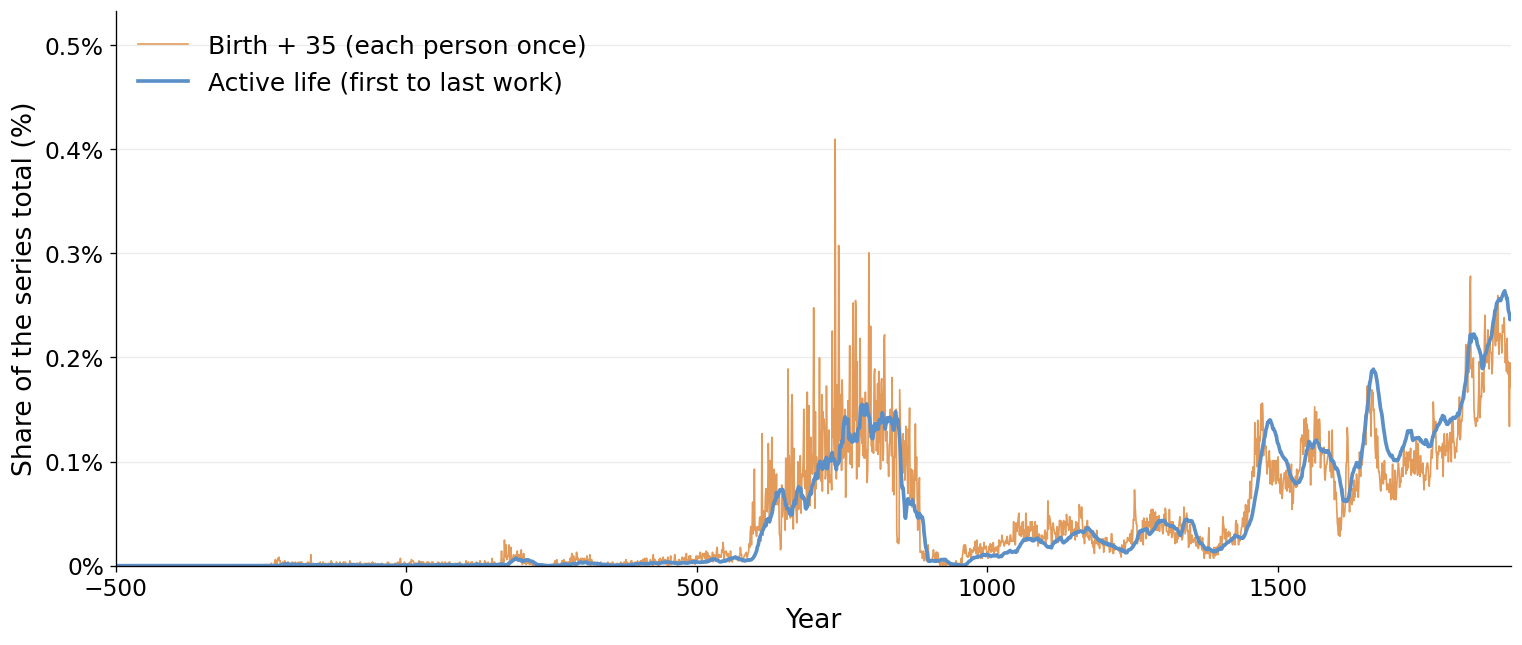

In [9]:
plot_series(yearly, ['birth_35', 'active_life'], (FIRST_YEAR, LAST_YEAR))

### Figure: birth + 35 vs active life, Ming–Qing transition

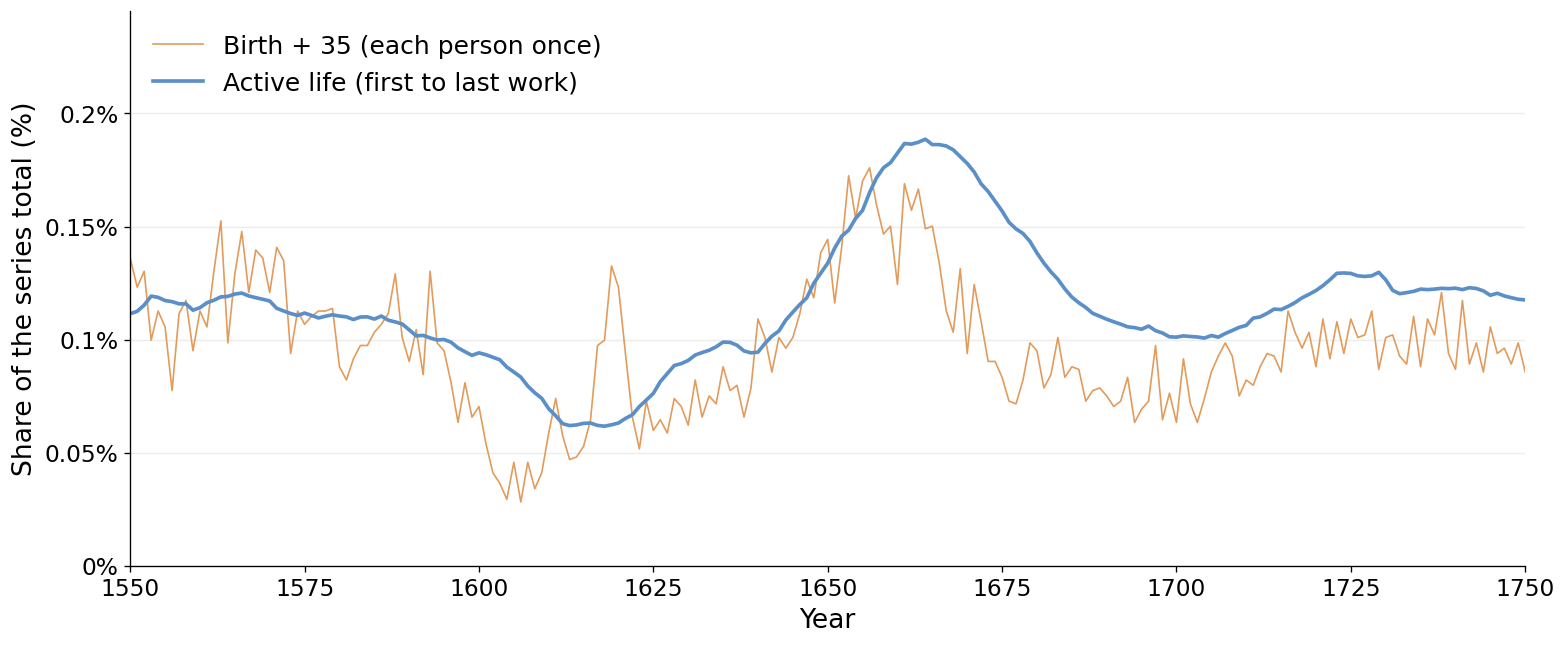

In [10]:
plot_series(zoom, ['birth_35', 'active_life'], (ZOOM_FIRST, ZOOM_LAST))

### Figure: birth + 25–70 vs active life, Chinese world
The 25–70 window is the same for everyone and ignores death; the active life is each person's own.

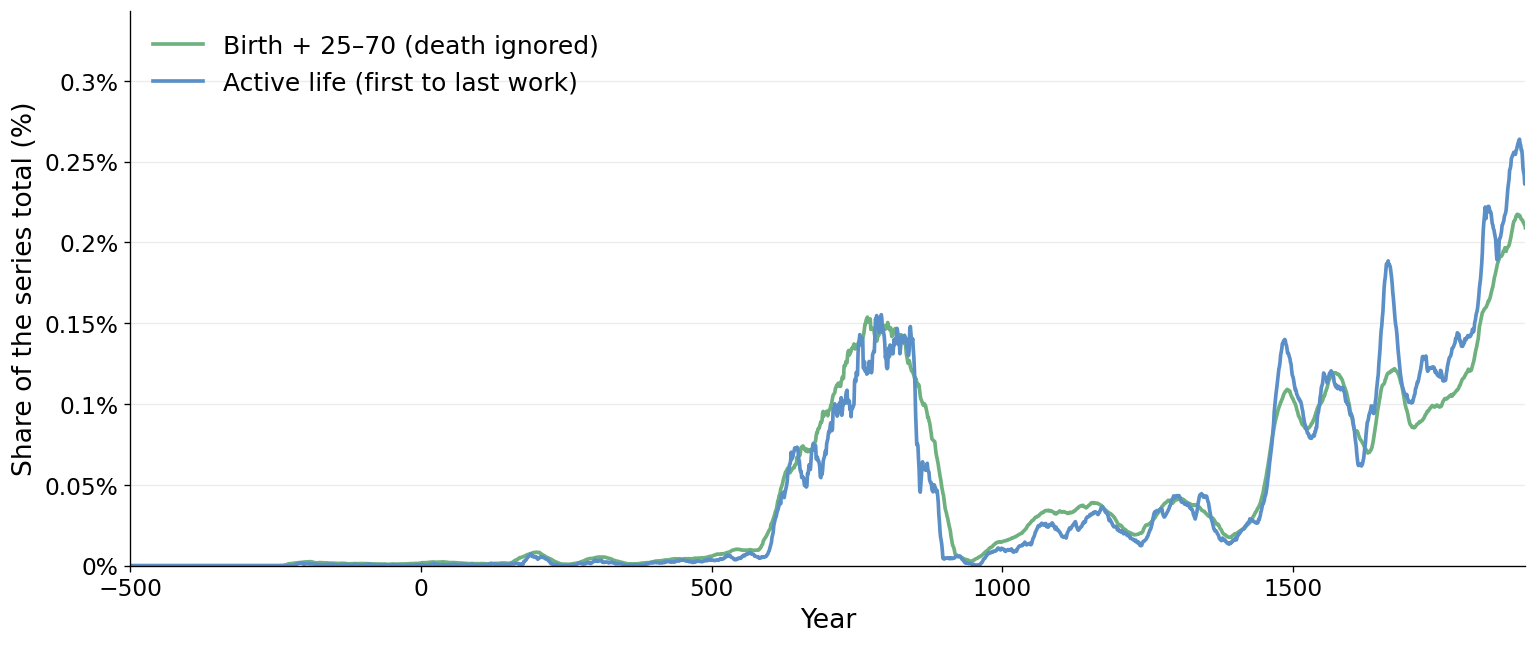

In [11]:
plot_series(yearly, ['wide_25_70', 'active_life'], (FIRST_YEAR, LAST_YEAR))

### Figure: birth + 25–70 vs active life, Ming–Qing transition

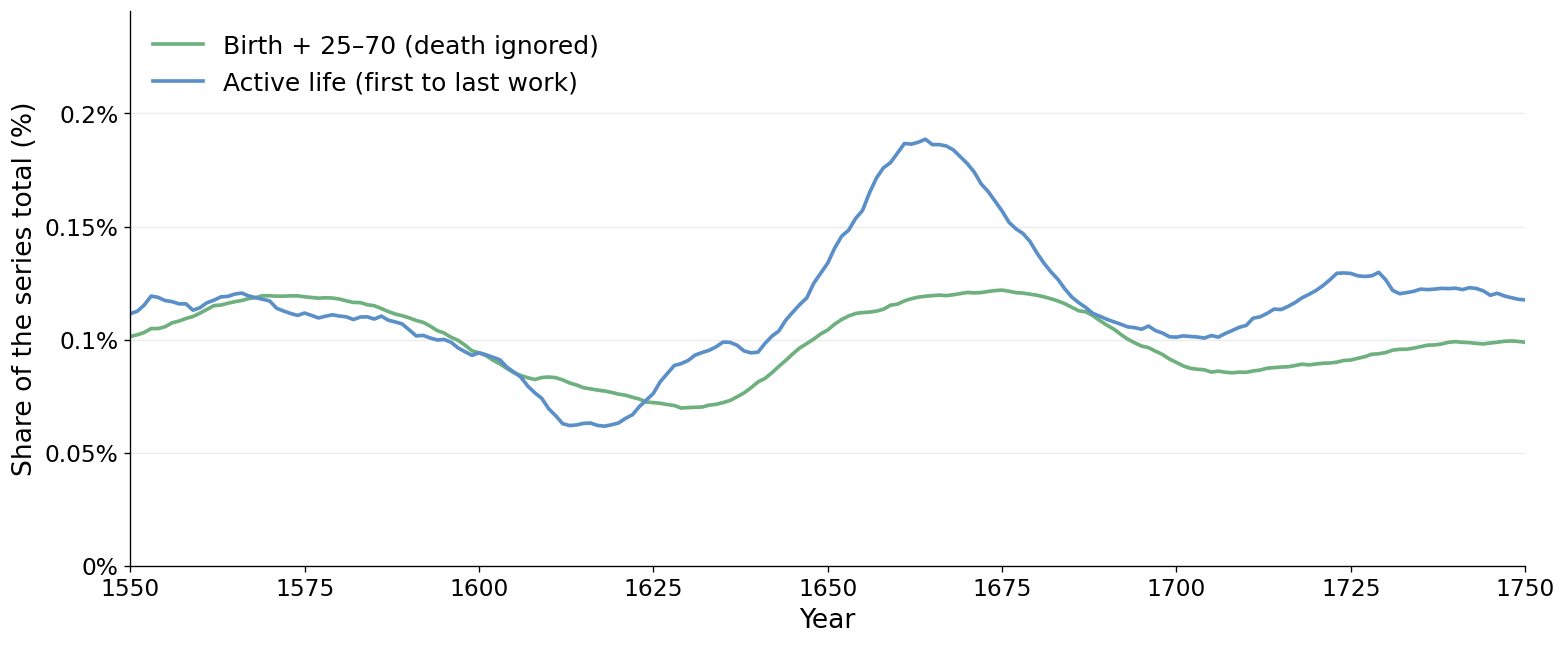

In [12]:
plot_series(zoom, ['wide_25_70', 'active_life'], (ZOOM_FIRST, ZOOM_LAST))